In [2]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

sys.path.insert(0, str(root))

from src.train import train
from src.predict import predict, load_model

# Проверяем исходные данные
for name in ["train", "validation", "test"]:
    data = pd.read_csv(root / "data" / f"{name}.csv")

    print(name)
    print("Размер:", data.shape)
    print("Пропуски:", data.isna().sum().to_dict())
    print("Дубликаты:", data.duplicated().sum())
    print("Метки:", data["label"].value_counts().to_dict())

# Обучаем модель
results = train()
load_model.cache_clear()

# Выводим метрики
for name in ["validation", "test"]:
    print("\n", name)
    print(pd.DataFrame(results[name]["classes"]).T)

print("Время обучения:", results["training_seconds"], "с")
print("Baseline accuracy:", results["baseline_accuracy"])

train
Размер: (11089, 2)
Пропуски: {'text': 0, 'label': 0}
Дубликаты: 37
Метки: {0: 6303, 1: 4786}
validation
Размер: (2101, 2)
Пропуски: {'text': 0, 'label': 0}
Дубликаты: 0
Метки: {1: 1051, 0: 1050}
test
Размер: (2101, 2)
Пропуски: {'text': 0, 'label': 0}
Дубликаты: 0
Метки: {1: 1051, 0: 1050}
train: 11089 -> 11050
validation: 2101 -> 2101
test: 2101 -> 2101
После проверки пересечений:
Train: 11046
Validation: 1985
Test: 2101
Accuracy: 0.9343
F1 INJECTION: 0.9302
Majority baseline: 0.4998
Training time: 0.23 s

 validation
              precision    recall  f1-score      support
0              0.960148  0.993289  0.976437  1043.000000
1              0.992274  0.954352  0.972944   942.000000
accuracy       0.974811  0.974811  0.974811     0.974811
macro avg      0.976211  0.973821  0.974691  1985.000000
weighted avg   0.975394  0.974811  0.974779  1985.000000

 test
              precision    recall  f1-score      support
0              0.888416  0.993333  0.937950  1050.000000
1     

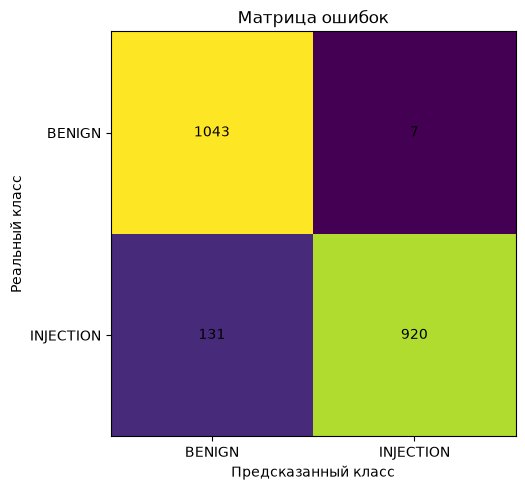

In [3]:
cm = results["test"]["matrix"]

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm)

ax.set_xticks([0, 1], ["BENIGN", "INJECTION"])
ax.set_yticks([0, 1], ["BENIGN", "INJECTION"])
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Реальный класс")
ax.set_title("Матрица ошибок")

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i][j], ha="center", va="center")

plt.tight_layout()
plt.savefig(root / "notebooks" / "confusion_matrix.png")
plt.show()

In [4]:
from src.train import load

test = load("test").sample(20, random_state=42)

def change_text(text):
    if "e" in text:
        return text.replace("e", "3", 1)
    if "a" in text:
        return text.replace("a", "@", 1)
    if len(text) < 10000:
        return text + "!"
    return text[:-1] + "!"

original = test["text"].tolist()
modified = [change_text(text) for text in original]

before = [predict(text) for text in original]
after = [predict(text) for text in modified]

labels = test["label"].tolist()

changed = sum(a != b for a, b in zip(before, after))
accuracy_before = sum(a == b for a, b in zip(before, labels)) / 20
accuracy_after = sum(a == b for a, b in zip(after, labels)) / 20

print("Всего запросов:", len(original))
print("Изменившихся предсказаний:", changed)
print("Доля изменившихся:", changed / 20)
print("Accuracy до:", accuracy_before)
print("Accuracy после:", accuracy_after)

pd.DataFrame({
    "Истинный класс": labels,
    "До изменения": before,
    "После изменения": after
})

test: 2101 -> 2101
Всего запросов: 20
Изменившихся предсказаний: 0
Доля изменившихся: 0.0
Accuracy до: 0.95
Accuracy после: 0.95


,Истинный класс,До изменения,После изменения
0,1,1,1
1,0,0,0
2,1,1,1
3,0,0,0
4,0,0,0
5,0,0,0
6,0,0,0
7,0,0,0
8,0,0,0
9,1,1,1


In [5]:
unusual = "hello " * 1000

print("Длина:", len(unusual))
print("99-й процентиль длины:", test["text"].str.len().quantile(0.99))
print("Предсказание:", predict(unusual))

Длина: 6000
99-й процентиль длины: 110.87999999999994
Предсказание: 0
